# Comparison Analysis on Apriori and FP-Growth

**Dataset:** `Market_Basket_Analysis.csv` &nbsp;|&nbsp; **Minimum support:** 0.003 &nbsp;|&nbsp; **Minimum confidence:** 0.2


In [2]:


import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlxtend
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules


warnings.filterwarnings("ignore", category=DeprecationWarning, module="jupyter_client")

MIN_SUPPORT = 0.003
MIN_CONFIDENCE = 0.2

## 1. Load and Inspect the Dataset

Each row of the file is one transaction, and each cell holds one purchased item or is blank. The first row is real data, not a header, so the file is loaded with `header=None`.

In [3]:
df = pd.read_csv("Market_Basket_Analysis.csv", header=None)

print("Shape:", df.shape)
display(df.head())

print("Total blank (NaN) cells:", df.isna().sum().sum())

first_row = df.iloc[0].dropna().tolist()
print("\nFirst row as a transaction:", first_row)
print("Number of items in it:", len(first_row))

Shape: (7501, 20)


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
0,shrimp,almonds,avocado,vegetables mix,green grapes,whole weat flour,yams,cottage cheese,energy drink,tomato juice,low fat yogurt,green tea,honey,salad,mineral water,salmon,antioxydant juice,frozen smoothie,spinach,olive oil
1,burgers,meatballs,eggs,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,chutney,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,turkey,avocado,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,mineral water,milk,energy bar,whole wheat rice,green tea,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Total blank (NaN) cells: 120657

First row as a transaction: ['shrimp', 'almonds', 'avocado', 'vegetables mix', 'green grapes', 'whole weat flour', 'yams', 'cottage cheese', 'energy drink', 'tomato juice', 'low fat yogurt', 'green tea', 'honey', 'salad', 'mineral water', 'salmon', 'antioxydant juice', 'frozen smoothie', 'spinach', 'olive oil']
Number of items in it: 20


## 2. Prepare Transaction Data


In [4]:
transactions = [
    [str(item).strip() for item in row if pd.notna(item) and str(item).strip()]
    for row in df.values.tolist()
]

print("Transactions:", len(transactions))
print("Total items:", sum(len(t) for t in transactions))
print("Empty transactions:", sum(len(t) == 0 for t in transactions))
print("Sample:", transactions[1])

te = TransactionEncoder()
basket = pd.DataFrame(te.fit(transactions).transform(transactions), columns=te.columns_)

print("\nEncoded shape:", basket.shape)
display(basket.iloc[:5, :8])

Transactions: 7501
Total items: 29363
Empty transactions: 0
Sample: ['burgers', 'meatballs', 'eggs']

Encoded shape: (7501, 119)


,almonds,antioxydant juice,asparagus,avocado,babies food,bacon,barbecue sauce,black tea
0,True,True,False,True,False,False,False,False
1,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False
3,False,False,False,True,False,False,False,False
4,False,False,False,False,False,False,False,False


## 3. Apriori and Association Rules

Frequent itemsets are mined with `min_support = 0.003`, then rules are generated with `min_threshold = 0.2` on confidence. Only the mining call is timed, so rule generation is not included in the time.

In [5]:
start = time.perf_counter()
apriori_itemsets = apriori(basket, min_support=MIN_SUPPORT, use_colnames=True)
apriori_time = time.perf_counter() - start

print("Apriori frequent itemsets:", len(apriori_itemsets))
print(f"Apriori mining time: {apriori_time:.4f} s")

if apriori_itemsets.empty:
    apriori_rules = pd.DataFrame()
    print("No frequent itemsets found, so no rules were generated.")
else:
    apriori_rules = association_rules(
        apriori_itemsets, metric="confidence", min_threshold=MIN_CONFIDENCE
    )
    print("Apriori rules:", len(apriori_rules))

rule_cols = ["antecedents", "consequents", "support", "confidence", "lift"]
if not apriori_rules.empty:
    display(apriori_rules[rule_cols].head(10))

Apriori frequent itemsets: 1443
Apriori mining time: 1.1998 s
Apriori rules: 1362


,antecedents,consequents,support,confidence,lift
0,(almonds),(burgers),0.005199,0.254902,2.923577
1,(almonds),(chocolate),0.005999,0.294118,1.795099
2,(almonds),(eggs),0.006532,0.320261,1.782108
3,(almonds),(french fries),0.004399,0.215686,1.261983
4,(almonds),(green tea),0.005066,0.248366,1.879913
5,(almonds),(milk),0.005199,0.254902,1.967098
6,(almonds),(mineral water),0.007599,0.372549,1.562914
7,(almonds),(spaghetti),0.005999,0.294118,1.689262
8,(avocado),(chocolate),0.007066,0.212000,1.293907
9,(avocado),(french fries),0.007999,0.240000,1.404243


## 4. FP-Growth and Association Rules

Same encoded data (`basket`) and the same thresholds as Apriori, so the comparison is fair.

In [6]:
start = time.perf_counter()
fp_itemsets = fpgrowth(basket, min_support=MIN_SUPPORT, use_colnames=True)
fp_time = time.perf_counter() - start

print("FP-Growth frequent itemsets:", len(fp_itemsets))
print(f"FP-Growth mining time: {fp_time:.4f} s")

if fp_itemsets.empty:
    fp_rules = pd.DataFrame()
    print("No frequent itemsets found, so no rules were generated.")
else:
    fp_rules = association_rules(
        fp_itemsets, metric="confidence", min_threshold=MIN_CONFIDENCE
    )
    print("FP-Growth rules:", len(fp_rules))

if not fp_rules.empty:
    display(fp_rules[rule_cols].head(10))

FP-Growth frequent itemsets: 1443
FP-Growth mining time: 33.4196 s
FP-Growth rules: 1362


,antecedents,consequents,support,confidence,lift
0,(green tea),(mineral water),0.031063,0.235116,0.986357
1,(green tea),(spaghetti),0.026530,0.200807,1.153335
2,(green tea),(french fries),0.028530,0.215943,1.263488
3,"(green tea, mineral water)",(spaghetti),0.008266,0.266094,1.528311
4,"(green tea, spaghetti)",(mineral water),0.008266,0.311558,1.307044
5,"(green tea, spaghetti)",(french fries),0.005333,0.201005,1.176083
6,"(french fries, green tea)",(mineral water),0.006133,0.214953,0.901770
7,"(chocolate, green tea)",(spaghetti),0.007066,0.301136,1.729574
8,"(green tea, spaghetti)",(chocolate),0.007066,0.266332,1.625512
9,"(chocolate, green tea)",(mineral water),0.006932,0.295455,1.239488


## 5. Comparison and Findings

**Check 1: are the results identical?** Itemsets and rules are matched by content, not by row position, so the different row order of the two algorithms does not matter.

In [7]:
def to_key(df, cols):
    out = df.copy()
    for c in cols:
        out[c] = out[c].apply(lambda s: tuple(sorted(s)))
    return out

a = to_key(apriori_itemsets, ["itemsets"]).set_index("itemsets")["support"]
f = to_key(fp_itemsets, ["itemsets"]).set_index("itemsets")["support"]

print("Same set of itemsets:", set(a.index) == set(f.index))
common = a.index.intersection(f.index)
print("Max support difference:", (a[common] - f[common]).abs().max())

if not apriori_rules.empty and not fp_rules.empty:
    rc = ["antecedents", "consequents"]
    ar = to_key(apriori_rules, rc)[rc + ["support", "confidence", "lift"]]
    fr = to_key(fp_rules, rc)[rc + ["support", "confidence", "lift"]]
    m = ar.merge(fr, on=rc, suffixes=("_ap", "_fp"))
    print("Rules matched:", len(m), "of", len(ar), "(Apriori) and", len(fr), "(FP-Growth)")
    print("Confidence equal:", np.allclose(m["confidence_ap"], m["confidence_fp"]))
    print("Lift equal:", np.allclose(m["lift_ap"], m["lift_fp"]))

Same set of itemsets: True
Max support difference: 0.0
Rules matched: 1362 of 1362 (Apriori) and 1362 (FP-Growth)
Confidence equal: True
Lift equal: True


**Check 2: execution time.** Each mining step is repeated 3 times, and the mean is reported, because a single run can be misleading.

In [8]:
print("mlxtend version:", mlxtend.__version__)

def time_runs(func, runs=3):
    times = []
    for _ in range(runs):
        t = time.perf_counter()
        func(basket, min_support=MIN_SUPPORT, use_colnames=True)
        times.append(time.perf_counter() - t)
    return times

ap_times = time_runs(apriori)
fp_times = time_runs(fpgrowth)

comparison = pd.DataFrame({
    "Algorithm": ["Apriori", "FP-Growth"],
    "Frequent itemsets": [len(apriori_itemsets), len(fp_itemsets)],
    "Rules": [len(apriori_rules), len(fp_rules)],
    "Mean time (s)": [np.mean(ap_times), np.mean(fp_times)],
    "Min time (s)": [min(ap_times), min(fp_times)],
})
display(comparison.round(4))
print("Apriori runs:", [round(t, 2) for t in ap_times])
print("FP-Growth runs:", [round(t, 2) for t in fp_times])

mlxtend version: 0.23.4


,Algorithm,Frequent itemsets,Rules,Mean time (s),Min time (s)
0,Apriori,1443,1362,1.3747,1.2206
1,FP-Growth,1443,1362,28.0231,27.6763


Apriori runs: [1.31, 1.6, 1.22]
FP-Growth runs: [28.18, 28.21, 27.68]


### Visualization: Execution Time Comparison

The bar chart compares the mean time of the frequent-itemset mining step (average of three runs, `min_support = 0.003`). Both algorithms returned identical results, so the difference is purely in speed.

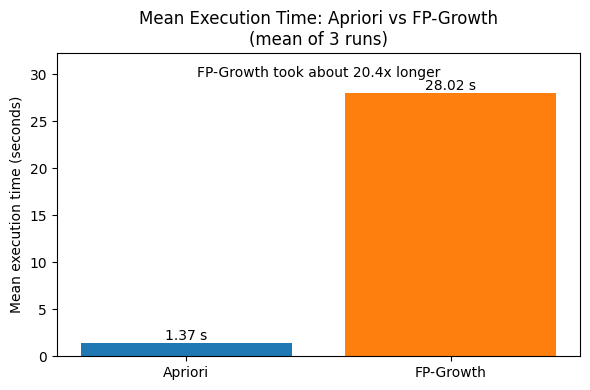

In [13]:

mean_times = comparison.set_index("Algorithm")["Mean time (s)"]
ratio = mean_times["FP-Growth"] / mean_times["Apriori"]

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(mean_times.index, mean_times.values, color=["tab:blue", "tab:orange"])


for bar, value in zip(bars, mean_times.values):
    ax.text(bar.get_x() + bar.get_width() / 2, value, f"{value:.2f} s",
            ha="center", va="bottom")

ax.set_title("Mean Execution Time: Apriori vs FP-Growth\n(mean of 3 runs)")

ax.set_ylabel("Mean execution time (seconds)")
ax.set_ylim(0, mean_times.max() * 1.15)


ax.text(0.5, 0.92, f"FP-Growth took about {ratio:.1f}x longer",
        transform=ax.transAxes, ha="center")

plt.tight_layout()
plt.show()

## 6. Observations

### Visualization: Association Rule Analysis

Each point is one association rule from the mining run (the Apriori rules are plotted, since FP-Growth produced an identical set). Its position shows support (x-axis) and confidence (y-axis), and its colour shows lift.

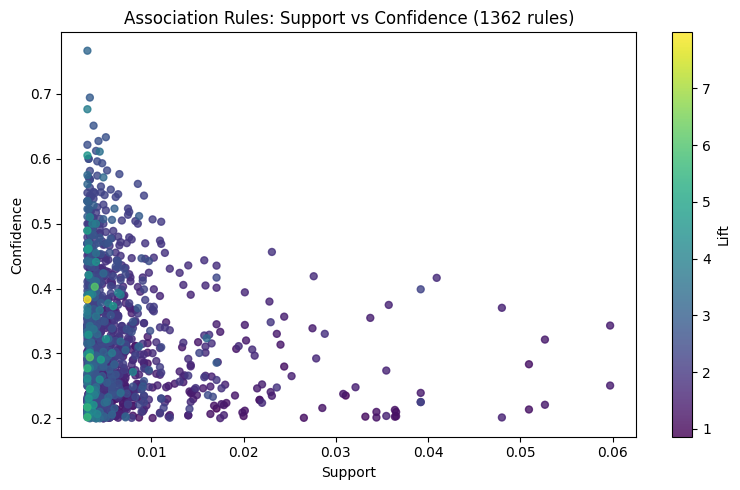

In [10]:
if apriori_rules.empty:
    print("No rules available to plot.")
else:
    # Sort by lift so the high-lift (bright) points are drawn last and stay visible
    plot_rules = apriori_rules.sort_values("lift")

    fig, ax = plt.subplots(figsize=(8, 5))
    scatter = ax.scatter(
        plot_rules["support"],
        plot_rules["confidence"],
        c=plot_rules["lift"],      # colour of each point = its lift value
        cmap="viridis",
        s=25,
        alpha=0.8,
    )

    colorbar = fig.colorbar(scatter, ax=ax)
    colorbar.set_label("Lift")

    ax.set_title(f"Association Rules: Support vs Confidence ({len(plot_rules)} rules)")
    ax.set_xlabel("Support")
    ax.set_ylabel("Confidence")

    plt.tight_layout()
    plt.show()



### Strongest rules



In [11]:
def readable(df):
    out = df[rule_cols].copy()
    for c in ["antecedents", "consequents"]:
        out[c] = out[c].apply(lambda s: ", ".join(sorted(s)))
    return out.round(4)

print("Top 10 rules by lift:")
display(readable(apriori_rules.sort_values("lift", ascending=False).head(10)))

print("Top 10 rules by confidence:")
display(readable(apriori_rules.sort_values("confidence", ascending=False).head(10)))

print("Top 10 rules by lift, with support >= 0.01:")
display(readable(
    apriori_rules[apriori_rules["support"] >= 0.01]
    .sort_values("lift", ascending=False).head(10)
))

Top 10 rules by lift:


,antecedents,consequents,support,confidence,lift
1318,"frozen vegetables, soup","milk, mineral water",0.0031,0.3833,7.9872
1313,"frozen vegetables, olive oil","milk, mineral water",0.0033,0.2941,6.1283
1160,"mineral water, whole wheat pasta",olive oil,0.0039,0.4028,6.1159
1319,"milk, soup","frozen vegetables, mineral water",0.0031,0.2018,5.6469
1073,tomato sauce,"ground beef, spaghetti",0.0031,0.2170,5.5360
1315,"frozen vegetables, milk, mineral water",soup,0.0031,0.2771,5.4844
166,fromage blanc,honey,0.0033,0.2451,5.1643
1072,"spaghetti, tomato sauce",ground beef,0.0031,0.4894,4.9806
58,light cream,chicken,0.0045,0.2906,4.8440
139,pasta,escalope,0.0059,0.3729,4.7008


Top 10 rules by confidence:


,antecedents,consequents,support,confidence,lift
1314,"frozen vegetables, milk, soup",mineral water,0.0031,0.7667,3.2163
1309,"frozen vegetables, milk, olive oil",mineral water,0.0033,0.6944,2.9133
434,"cereals, ground beef",spaghetti,0.0031,0.6765,3.8853
1295,"frozen vegetables, ground beef, milk",mineral water,0.0037,0.6512,2.7318
953,"frozen vegetables, soup",mineral water,0.0051,0.6333,2.6570
1162,"pancakes, soup",mineral water,0.0043,0.6275,2.6323
1356,"milk, shrimp, spaghetti",mineral water,0.0031,0.6216,2.6078
1203,"chocolate, eggs, ground beef",mineral water,0.0040,0.6122,2.5685
1190,"olive oil, tomatoes",spaghetti,0.0044,0.6111,3.5099
1316,"frozen vegetables, mineral water, soup",milk,0.0031,0.6053,4.6709


Top 10 rules by lift, with support >= 0.01:


,antecedents,consequents,support,confidence,lift
188,herb & pepper,ground beef,0.0160,0.3235,3.2920
1052,"mineral water, spaghetti",ground beef,0.0171,0.2857,2.9079
177,tomatoes,frozen vegetables,0.0161,0.2359,2.4745
175,shrimp,frozen vegetables,0.0167,0.2332,2.4466
931,"milk, mineral water",frozen vegetables,0.0111,0.2306,2.4187
1051,"ground beef, mineral water",spaghetti,0.0171,0.4169,2.3947
930,"frozen vegetables, mineral water",milk,0.0111,0.3097,2.3900
1028,"milk, mineral water",ground beef,0.0111,0.2306,2.3465
226,soup,milk,0.0152,0.3008,2.3212
197,spaghetti,ground beef,0.0392,0.2251,2.2912
